# 1. TOP 20 MOMENTUM (US LARGE CAPS) - HYPOTHESIS DEFINITION & BASELINE BACKTEST
Long-only tactical rotation (TIS Strategy #4, **Top 20** version) on a point-in-time S&P 500 universe, daily bars, real costs (slippage per side) and next-open execution.

### 1.1 CORE HYPOTHESIS
Stocks with the strongest 3-month return keep outperforming the eligible universe over the next month, and a trend filter (SPY > SMA200, stock > SMA200) cuts the drawdowns of bear markets.
### 1.2 FROZEN RULES (TIS, not fitted)
1. First Wednesday of the month (signal at the close, trade at the next open). 2. Eligible: S&P 500 member, avg volume >= 2M sh, price > SMA200 and SMA50.
3. Rank by 63-day return, buy the Top N (N = 20) equal weight; held names that stay in the Top N are not touched.
4. SPY < SMA200 -> sell everything, cash until the next monthly rebalance. 5. Weekly check: stock < own SMA200 -> sell it, cash until the next rebalance.
### 1.3 HOW IT IS JUDGED
Every PASS / FAIL is registered; section 6 groups them into a GO / STOP gate. Statistics are at **portfolio level** (monthly returns): trade-level t-stats are inflated because the 20 positions are correlated.
Top 20 (instead of the Top 10 in the TIS PDF) is a variant TIS documents itself (CAGR 13-15%, Sharpe ~0.70, MaxDD ~-28%); it is declared a priori, not chosen from our results.

In [3]:
%pip install lxml yfinance requests
from t20_tools import *
from scipy import stats
VARIANT = "t20_sp500_v1"
S = setup(VARIANT)
eng, P, rules, panel, TH, reg = S.eng, S.P, S.rules, S.panel, S.TH, S.reg
check, OOS, CAP, LIMIT, N = reg.check, S.OOS, S.CAP, S.LIMIT, S.P["top_n"]


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Data missing or refresh requested ({'ok': False, 'n_files': 0, 'has_benchmark': False, 'has_membership': False, 'last_bar': None, 'age_days': None, 'max_age_days': 45}). Downloading from free sources (one-off, can take 10-20 min)...
   Wikipedia attempt failed (https://en.wikipedia.org/wiki/List_of_S%26P_500_companies): Could not find the Wikipedia tables (current=True, changes=False). Tables seen (index, shape, columns): [(0, (503, 8), ['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location']), (1, (11, 2), ['.mw-parser-output .navbar', '.mw-parser-output .navbar'])]
   Wikipedia attempt failed (https://en.wikipedia.org/wiki/List_of_S%26P_500_companies): Could not find the Wikipedia tables (current=True, changes=False). Tables seen (index

## 2. BASELINE RUN (FROZEN RULES) AND IN-SAMPLE / OUT-OF-SAMPLE
The strategy is simulated ONCE on the full history (indicators keep their warm-up); IS / OOS only slice the result by date.

In [4]:
full = eng.run_backtest(panel, **rules)
ret, trades, npos = full["ret"], full["trades"], full["npos"]
bh = eng.benchmark_ret(panel, ret)
print(f"{ret.index[0]:%Y-%m-%d} -> {ret.index[-1]:%Y-%m-%d} | closed trades {int((trades.reason != 'open').sum())} | avg positions {npos.mean():.1f} | days in cash {100 * (npos == 0).mean():.0f}%")

def block(mask):
    r = ret[mask]; m, b = eng.perf(r), eng.perf(bh[mask]); mon = eng.monthly(r)
    t = trades[(trades.reason != "open") & trades.entry_time.between(r.index[0], r.index[-1])]; ts = eng.trade_stats(t)
    return dict(CAGR=m["cagr"], Sharpe=m["sharpe"], MaxDD=m["max_dd"], Vol=m["vol"], SPY_CAGR=b["cagr"], SPY_Sharpe=b["sharpe"], SPY_MaxDD=b["max_dd"],
                Trades=ts["n"], PF=ts["pf"], Win=ts["win_pct"], Payoff=ts["payoff"], t_month=eng.tstat(mon), AvgDays=ts["avg_days"])
idx = ret.index
tab = pd.DataFrame({"IS": block(idx < OOS), "OOS": block(idx >= OOS), "All": block(np.ones(len(idx), bool))}).T
print(tab.round(3).to_string())

2003-10-20 -> 2026-11-09 | closed trades 2848 | avg positions 15.1 | days in cash 24%
      CAGR  Sharpe  MaxDD    Vol  SPY_CAGR  SPY_Sharpe  SPY_MaxDD  Trades     PF     Win  Payoff  t_month  AvgDays
IS   0.097   0.687 -0.195  0.151     0.081       0.518     -0.552  1859.0  1.658  49.704   1.678    2.955   31.109
OOS  0.120   0.626 -0.299  0.221     0.168       0.904     -0.337   989.0  1.586  48.837   1.662    1.781   30.109
All  0.105   0.649 -0.299  0.178     0.110       0.654     -0.552  2848.0  1.626  49.403   1.665    3.292   30.762


## 3. EXPLORATORY CHECKS OF THE HYPOTHESIS
### 3.1 DOES PAST 3-MONTH RETURN PREDICT THE NEXT MONTH? (CROSS-SECTION, NO COSTS)
At every rebalance date: forward 21-day return of the Top N vs the average of the whole eligible universe, plus the rank correlation (IC) between momentum and forward return.

252 rebalances | mean forward 21d: Top 20 +1.22% vs universe +0.94% | excess +0.28% (t 1.70) | IC -0.008 (t -0.72) | eligible names 114
   [FAIL] Top 20 beats the eligible universe (t of monthly excess >= 2)  ->  excess +0.28% / month, t 1.70
   [FAIL] Information coefficient > 0 (t >= 2)  ->  IC -0.008, t -0.72


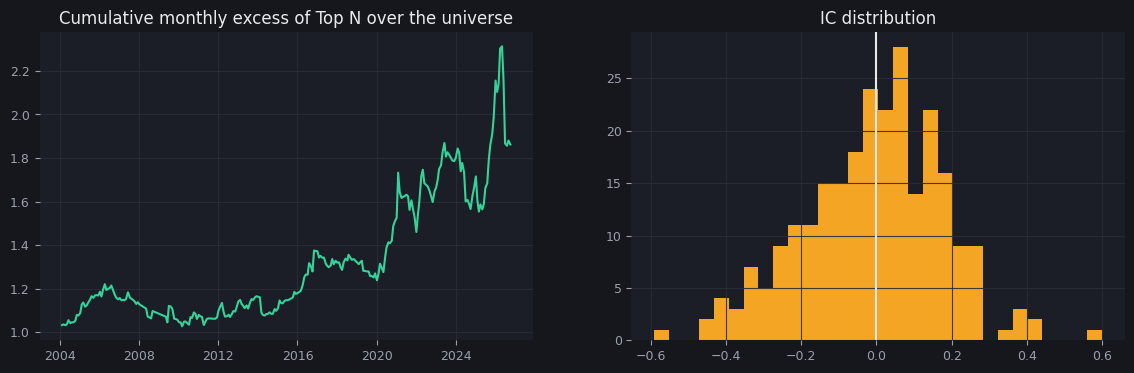

In [5]:
reb, _ = eng.calendar_flags(panel.dates, rules["rebalance"])
mom, smaS, smaF = panel.mom(rules["lookback_days"]), panel.sma(rules["stock_ma"]), panel.sma(rules["fast_ma"])
rows = []
for t in np.flatnonzero(reb):
    if t < 260 or t + 21 >= len(panel.dates): continue
    el = panel.member[t] & ~np.isnan(mom[t]) & (panel.adv[t] >= rules["min_adv_shares"]) & (panel.close[t] > smaS[t]) & (panel.close[t] > smaF[t])
    ix = np.flatnonzero(el)
    if len(ix) < 2 * N: continue
    fwd = panel.close_ff[t + 21, ix] / panel.close_ff[t, ix] - 1; top = np.argsort(-mom[t, ix])[:N]
    rows.append(dict(date=panel.dates[t], top=fwd[top].mean(), uni=fwd.mean(), ic=stats.spearmanr(mom[t, ix], fwd)[0], n=len(ix)))
xs = pd.DataFrame(rows).set_index("date"); xs["excess"] = xs["top"] - xs["uni"]
t_ex, t_ic = eng.tstat(xs["excess"]), eng.tstat(xs["ic"])
print(f"{len(xs)} rebalances | mean forward 21d: Top {N} {100 * xs['top'].mean():+.2f}% vs universe {100 * xs['uni'].mean():+.2f}% | excess {100 * xs['excess'].mean():+.2f}% (t {t_ex:.2f}) | IC {xs['ic'].mean():+.3f} (t {t_ic:.2f}) | eligible names {xs['n'].median():.0f}")
check("3.1 Signal", f"Top {N} beats the eligible universe (t of monthly excess >= {TH['T_MIN']:g})", t_ex >= TH["T_MIN"], f"excess {100 * xs['excess'].mean():+.2f}% / month, t {t_ex:.2f}")
check("3.1 Signal", f"Information coefficient > 0 (t >= {TH['T_MIN']:g})", t_ic >= TH["T_MIN"], f"IC {xs['ic'].mean():+.3f}, t {t_ic:.2f}")
f, ax = fig(1, 2, figsize=(14, 4)); ax[0].plot((1 + xs["excess"]).cumprod(), color=GREEN); ax[0].set_title("Cumulative monthly excess of Top N over the universe")
ax[1].hist(xs["ic"], bins=30, color=ORANGE); ax[1].axvline(0, color=TXT); ax[1].set_title("IC distribution"); plt.show()

### 3.2 THE STRATEGY VS THE BENCHMARKS (SPY BUY & HOLD, EQUAL-WEIGHT ELIGIBLE UNIVERSE)

Strategy: CAGR 10.5% Sharpe 0.65 MaxDD -29.9% | SPY: CAGR 11.0% Sharpe 0.65 MaxDD -55.2%
   [FAIL] Sharpe above SPY buy & hold (full period)  ->  0.65 vs 0.65
   [PASS] Max drawdown shallower than SPY buy & hold  ->  -29.9% vs -55.2%


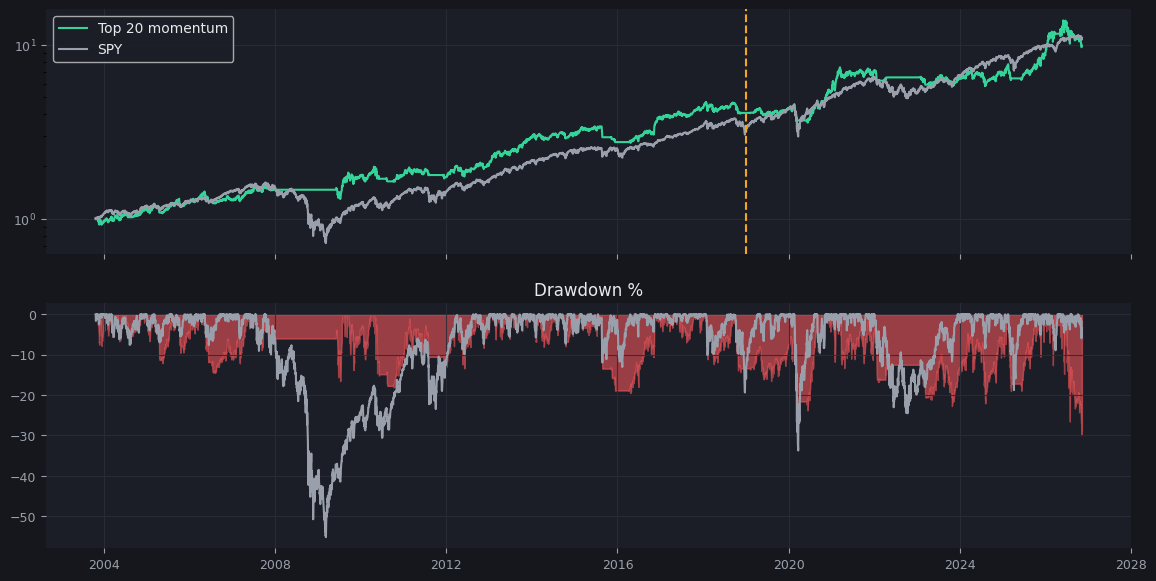

In [6]:
uni_m = xs["uni"]                                    # monthly forward return of the equal-weight eligible universe (diagnostic)
b_all, m_all = eng.perf(bh), eng.perf(ret)
print(f"Strategy: CAGR {100 * m_all['cagr']:.1f}% Sharpe {m_all['sharpe']:.2f} MaxDD {100 * m_all['max_dd']:.1f}% | SPY: CAGR {100 * b_all['cagr']:.1f}% Sharpe {b_all['sharpe']:.2f} MaxDD {100 * b_all['max_dd']:.1f}%")
check("3.2 Benchmarks", "Sharpe above SPY buy & hold (full period)", m_all["sharpe"] > b_all["sharpe"], f"{m_all['sharpe']:.2f} vs {b_all['sharpe']:.2f}")
check("3.2 Benchmarks", "Max drawdown shallower than SPY buy & hold", m_all["max_dd"] > b_all["max_dd"], f"{100 * m_all['max_dd']:.1f}% vs {100 * b_all['max_dd']:.1f}%")
f, ax = fig(2, 1, figsize=(14, 7), sharex=True); ax[0].plot((1 + ret).cumprod(), color=GREEN, label="Top 20 momentum"); ax[0].plot((1 + bh).cumprod(), color=SUB, label="SPY"); ax[0].set_yscale("log")
ax[0].axvline(OOS, color=ORANGE, ls="--"); ax[0].legend(facecolor=PANEL, labelcolor=TXT); ax[1].fill_between(idx, 100 * eng.drawdown(ret), color=RED, alpha=.6); ax[1].plot(100 * eng.drawdown(bh), color=SUB); ax[1].set_title("Drawdown %"); plt.show()

### 3.3 WHAT EACH FILTER CONTRIBUTES (SAME DATA, SAME COSTS)
Reference variants: the configured rules vs removing one piece at a time.

In [7]:
variants = {"Configured": {}, "No market filter (SPY)": dict(market_filter=False), "No stock SMA200 stop": dict(stock_stop=False),
            "No trend entry filter": dict(stock_trend=False), "Pure Top N (no filters)": dict(market_filter=False, stock_stop=False, stock_trend=False),
            "Same-close execution (TIS manual)": dict(exec_mode="close")}
rv = {k: eng.run_backtest(panel, **{**rules, **v}) for k, v in variants.items()}
vt = pd.DataFrame({k: {**eng.perf(r["ret"]), "PF": eng.trade_stats(r["trades"])["pf"], "trades": eng.trade_stats(r["trades"])["n"]} for k, r in rv.items()}).T[["cagr", "sharpe", "max_dd", "calmar", "PF", "trades"]]
print(vt.round(3).to_string())
check("3.3 Filters", "Configured rules beat pure Top N on Sharpe", vt.loc["Configured", "sharpe"] > vt.loc["Pure Top N (no filters)", "sharpe"], f"{vt.loc['Configured', 'sharpe']:.2f} vs {vt.loc['Pure Top N (no filters)', 'sharpe']:.2f}")
check("3.3 Filters", "Market filter reduces max drawdown", vt.loc["Configured", "max_dd"] > vt.loc["No market filter (SPY)", "max_dd"], f"{100 * vt.loc['Configured', 'max_dd']:.1f}% vs {100 * vt.loc['No market filter (SPY)', 'max_dd']:.1f}%")
check("3.3 Filters", "Next-open execution loses < 0.2 Sharpe vs same-close (look-ahead in the manual TIS rule is small)", vt.loc["Same-close execution (TIS manual)", "sharpe"] - vt.loc["Configured", "sharpe"] < 0.2,
      f"same-close {vt.loc['Same-close execution (TIS manual)', 'sharpe']:.2f} vs next-open {vt.loc['Configured', 'sharpe']:.2f}")

                                    cagr  sharpe  max_dd  calmar     PF  trades
Configured                         0.105   0.649  -0.299   0.350  1.626  2848.0
No market filter (SPY)             0.125   0.647  -0.533   0.234  1.649  3116.0
No stock SMA200 stop               0.104   0.642  -0.314   0.331  1.618  2845.0
No trend entry filter              0.109   0.668  -0.275   0.395  1.664  2812.0
Pure Top N (no filters)            0.145   0.662  -0.657   0.220  1.739  3048.0
Same-close execution (TIS manual)  0.111   0.687  -0.266   0.418  1.675  2848.0
   [FAIL] Configured rules beat pure Top N on Sharpe  ->  0.65 vs 0.66
   [PASS] Market filter reduces max drawdown  ->  -29.9% vs -53.3%
   [PASS] Next-open execution loses < 0.2 Sharpe vs same-close (look-ahead in the manual TIS rule is small)  ->  same-close 0.69 vs next-open 0.65


'PASS'

### 3.4 CONCENTRATION BY CALENDAR YEAR

In [8]:
an = eng.annual(ret, LIMIT); an["spy"] = [(1 + bh[bh.index.year == y]).prod() - 1 for y in an["year"]]
print(an.round(3).to_string(index=False))
full_y = an[~an["partial"]]; pos = (full_y["ret"] > 0).mean(); best = full_y.loc[full_y["ret"].idxmax(), "year"]
rest = eng.monthly(ret[ret.index.year != best]); t_rest = eng.tstat(rest)
check("3.4 Years", f"Share of profitable calendar years >= {TH['YEARS_POS_MIN']:.0%}", pos >= TH["YEARS_POS_MIN"], f"{pos:.0%} of {len(full_y)} years")
check("3.4 Years", "Monthly t-stat survives without the best year (>= 1.5)", t_rest >= 1.5, f"best year {best}, t without it {t_rest:.2f}")

 year    ret    mdd  days  partial  breach    spy
 2003 -0.032 -0.078    51     True   False  0.072
 2004  0.189 -0.067   252    False   False  0.107
 2005  0.065 -0.121   252    False   False  0.048
 2006  0.046 -0.145   251    False   False  0.158
 2007  0.146 -0.088   251    False   False  0.051
 2008  0.000  0.000   253    False   False -0.368
 2009  0.192 -0.137   252    False   False  0.264
 2010  0.018 -0.181   252    False   False  0.151
 2011 -0.025 -0.136   252    False   False  0.019
 2012  0.182 -0.134   250    False   False  0.160
 2013  0.448 -0.062   252    False   False  0.323
 2014  0.040 -0.080   252    False   False  0.135
 2015 -0.106 -0.189   252    False   False  0.012
 2016  0.361 -0.069   252    False   False  0.120
 2017  0.151 -0.069   251    False   False  0.217
 2018 -0.061 -0.143   251    False   False -0.046
 2019  0.059 -0.093   252    False   False  0.312
 2020  0.271 -0.218   253    False   False  0.183
 2021  0.288 -0.133   252    False   False  0.287


'PASS'

## 4. JUDGING THE BASELINE (IS / OOS)

In [9]:
g = tab
check("4. Baseline", f"Trades, full period >= {TH['N_MIN']}", g.loc["All", "Trades"] >= TH["N_MIN"], f"{int(g.loc['All', 'Trades'])}")
check("4. Baseline", f"Trades, OOS >= {TH['N_OOS_MIN']}", g.loc["OOS", "Trades"] >= TH["N_OOS_MIN"], f"{int(g.loc['OOS', 'Trades'])}")
check("4. Baseline", f"Sharpe, IS >= {TH['SHARPE_MIN']:g}", g.loc["IS", "Sharpe"] >= TH["SHARPE_MIN"], f"{g.loc['IS', 'Sharpe']:.2f}")
check("4. Baseline", f"Sharpe, OOS >= {TH['SHARPE_OOS_MIN']:g}", g.loc["OOS", "Sharpe"] >= TH["SHARPE_OOS_MIN"], f"{g.loc['OOS', 'Sharpe']:.2f}")
check("4. Baseline", f"Profit Factor, IS >= {TH['PF_MIN']:g}", g.loc["IS", "PF"] >= TH["PF_MIN"], f"{g.loc['IS', 'PF']:.2f}")
check("4. Baseline", f"Profit Factor, OOS >= {TH['PF_MIN']:g}", g.loc["OOS", "PF"] >= TH["PF_MIN"], f"{g.loc['OOS', 'PF']:.2f}")
check("4. Baseline", f"t-stat of monthly returns >= {TH['T_MIN']:g} (full)", g.loc["All", "t_month"] >= TH["T_MIN"], f"{g.loc['All', 't_month']:.2f} (IS {g.loc['IS', 't_month']:.2f} / OOS {g.loc['OOS', 't_month']:.2f})")
check("4. Baseline", "OOS Sharpe keeps at least half of the IS Sharpe", g.loc["OOS", "Sharpe"] >= 0.5 * g.loc["IS", "Sharpe"], f"{g.loc['OOS', 'Sharpe']:.2f} vs {g.loc['IS', 'Sharpe']:.2f}")

   [PASS] Trades, full period >= 100  ->  2848
   [PASS] Trades, OOS >= 30  ->  989
   [PASS] Sharpe, IS >= 0.5  ->  0.69
   [PASS] Sharpe, OOS >= 0.4  ->  0.63
   [PASS] Profit Factor, IS >= 1.3  ->  1.66
   [PASS] Profit Factor, OOS >= 1.3  ->  1.59
   [PASS] t-stat of monthly returns >= 2 (full)  ->  3.29 (IS 2.95 / OOS 1.78)
   [PASS] OOS Sharpe keeps at least half of the IS Sharpe  ->  0.63 vs 0.69


'PASS'

### 4.1 SIZING AND HARD LIMIT
Fully invested (equal weight 1/N). If the account rule is tighter than the strategy's drawdown, the allocated fraction is scaled linearly (rest idle cash).

In [10]:
dd = eng.perf(ret)["max_dd"]; frac = eng.fraction_for_limit(ret, LIMIT)
print(f"Max drawdown fully invested {100 * dd:.1f}% | hard limit -{LIMIT:.0%} | fraction of capital that respects it: {frac:.0%} | position size at capital {CAP:,.0f}: {CAP * frac / N:,.0f} each ({N} names)")
check("4.1 Hard limit", "Full allocation respects the hard limit", dd >= -LIMIT, f"{100 * dd:.1f}% vs -{LIMIT:.0%}")
check("4.1 Hard limit", "Position size >= 250 at the declared capital and the limit-fitted fraction", CAP * frac / N >= 250, f"{CAP * frac / N:,.0f} per position")
check("4.1 Hard limit", "No full calendar year breaches the limit (full allocation)", not an.loc[~an["partial"], "breach"].any(), f"breaches: {an.loc[an['breach'], 'year'].tolist()}")

Max drawdown fully invested -29.9% | hard limit -30% | fraction of capital that respects it: 100% | position size at capital 10,000: 500 each (20 names)
   [PASS] Full allocation respects the hard limit  ->  -29.9% vs -30%
   [PASS] Position size >= 250 at the declared capital and the limit-fitted fraction  ->  500 per position
   [PASS] No full calendar year breaches the limit (full allocation)  ->  breaches: []


'PASS'

## 5. SANITY CHECKS & VERIFICATION

In [11]:
viol = []
tr = trades[trades.reason != "open"]
ok200 = panel.spy_ok(rules["spy_ma"]); pos_of = {d: i for i, d in enumerate(panel.dates)}
rebs = set(panel.dates[np.flatnonzero(reb)])
ent = pd.DatetimeIndex(tr["entry_time"].unique())
for d in ent:                                                       # entries must be the next session after a rebalance day, with SPY above its SMA200 on the signal day
    i = pos_of[d]
    if panel.dates[i - 1] not in rebs: viol.append(f"entry {d:%Y-%m-%d} is not right after a rebalance day")
    elif not ok200[i - 1]: viol.append(f"entry {d:%Y-%m-%d} with SPY below its SMA200")
check("5. Sanity", "No lookahead: entries follow a rebalance close, market filter ON", not viol, f"{len(viol)} violations in {len(ent)} entry days" + (f" e.g. {viol[0]}" if viol else ""))
check("5. Sanity", f"Never more than {N} positions", int(npos.max()) <= N, f"max {int(npos.max())}")
mem_ok = all(panel.member[pos_of[d] - 1, panel.tickers.index(k)] for k, d in zip(tr["ticker"], tr["entry_time"]))
check("5. Sanity", "Point-in-time universe: every entry was an S&P 500 member on the signal date", mem_ok, f"{len(tr)} trades")
last_valid = panel.close_df.apply(lambda s: s.last_valid_index()); gone = (last_valid < panel.dates[-1] - pd.Timedelta(days=30)).mean()
check("5. Sanity", "Data include delisted names (survivorship): >= 5% of tickers stop trading", gone >= .05, f"{100 * gone:.1f}% of {len(panel.tickers)} tickers")
el_by_year = xs.groupby(xs.index.year)["n"].median()
check("5. Sanity", f"Eligible names >= 2 x Top N in every year", (el_by_year >= 2 * N).all(), f"min median {int(el_by_year.min())}")
print("Exit reasons:", tr["reason"].value_counts().to_dict(), "| avg holding days:", round(tr["days"].mean(), 1))

   [PASS] No lookahead: entries follow a rebalance close, market filter ON  ->  0 violations in 231 entry days
   [PASS] Never more than 20 positions  ->  max 20
   [PASS] Point-in-time universe: every entry was an S&P 500 member on the signal date  ->  2848 trades
   [FAIL] Data include delisted names (survivorship): >= 5% of tickers stop trading  ->  0.0% of 500 tickers
   [PASS] Eligible names >= 2 x Top N in every year  ->  min median 67
Exit reasons: {'rebalance': 2112, 'market_filter': 624, 'stop': 112} | avg holding days: 30.8


## 6. SUMMARY & GO / STOP GATE

In [12]:
ESSENTIAL = [
    ("5. Sanity", "No lookahead", "Fix the execution model first: every number is invalid until this passes."),
    ("5. Sanity", "Point-in-time universe", "The universe is not point-in-time: results are inflated by survivorship. Fix the membership file."),
    ("5. Sanity", "Data include delisted", "Use a database that includes delisted stocks (Norgate 'Current & Past')."),
    ("3.1 Signal", "Top", "Top N does not beat the eligible universe: the ranking has no cross-sectional edge."),
    ("3.2 Benchmarks", "Sharpe above SPY", "Sharpe does not beat SPY: no reason to run this instead of buy & hold."),
    ("3.3 Filters", "Configured rules beat pure", "The filters add nothing over pure Top N: simplify or reject."),
    ("3.3 Filters", "Market filter reduces", "The SPY filter does not reduce drawdown: the protection leg is not confirmed."),
    ("4. Baseline", "Sharpe, IS", "Baseline does not hold in-sample: do not optimize."),
    ("4. Baseline", "Sharpe, OOS", "Baseline does not hold out-of-sample: the edge is not confirmed."),
    ("4. Baseline", "Profit Factor, IS", "PF below the minimum in-sample."), ("4. Baseline", "Profit Factor, OOS", "PF below the minimum out-of-sample."),
    ("4. Baseline", "t-stat of monthly", "Monthly returns are not statistically significant: could be noise."),
    ("4. Baseline", "Trades, full", "Too few trades."), ("4. Baseline", "Trades, OOS", "Too few OOS trades."),
    ("4.1 Hard limit", "Full allocation", "Drawdown exceeds the account limit: scale the fraction (see 4.1) or do not trade it."),
]
go = gate(reg, ESSENTIAL, headline=f"| Sharpe {m_all['sharpe']:.2f} (SPY {b_all['sharpe']:.2f}) | CAGR {100 * m_all['cagr']:.1f}% | MaxDD {100 * m_all['max_dd']:.1f}%")
print("\nNEXT STEP:", "02_Top20_Momentum_Optimization.ipynb: is (63 d, Top 20) on a broad plateau, in-sample only?" if go else "fix the failed gates, or record the variant as rejected.")

DECISION: STOP  (11 PASS / 4 FAIL / 0 SKIP of 15 essential)  | Sharpe 0.65 (SPY 0.65) | CAGR 10.5% | MaxDD -29.9%

3.1 Signal
   [FAIL] Top 20 beats the eligible universe (t of monthly excess >= 2)  ->  excess +0.28% / month, t 1.70

3.2 Benchmarks
   [FAIL] Sharpe above SPY buy & hold (full period)  ->  0.65 vs 0.65

3.3 Filters
   [FAIL] Configured rules beat pure Top N on Sharpe  ->  0.65 vs 0.66
   [PASS] Market filter reduces max drawdown  ->  -29.9% vs -53.3%

4. Baseline
   [PASS] Trades, full period >= 100  ->  2848
   [PASS] Trades, OOS >= 30  ->  989
   [PASS] Sharpe, IS >= 0.5  ->  0.69
   [PASS] Sharpe, OOS >= 0.4  ->  0.63
   [PASS] Profit Factor, IS >= 1.3  ->  1.66
   [PASS] Profit Factor, OOS >= 1.3  ->  1.59
   [PASS] t-stat of monthly returns >= 2 (full)  ->  3.29 (IS 2.95 / OOS 1.78)

4.1 Hard limit
   [PASS] Full allocation respects the hard limit  ->  -29.9% vs -30%

5. Sanity
   [PASS] No lookahead: entries follow a rebalance close, market filter ON  ->  0 violati

## 7. SAVE

In [13]:
d = reg.df()
S.vc.save_json(S.cfg, "01_hypothesis.json", dict(variant=S.cfg["id"], go=bool(go), table=tab.round(4).to_dict("index"), filters=vt.round(4).to_dict("index"),
    fraction_for_limit=frac, checks=d.to_dict("records"), n_pass=int((d.status == "PASS").sum()), n_fail=int((d.status == "FAIL").sum())))

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Top20_Momentum/runs/t20_sp500_v1/01_hypothesis.json')